In [1]:
import openmc
import numpy as np
import openmc.deplete
from pathlib import Path
import structural_material_analysis as sma
import tokamak_radiation_environment as tre

/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/material.py:1512: UserWarning: Warning: sum of fractions do not add to 1, void fraction set to 0.09999999999999987
  warnings.warn(msg)


In [2]:
cross_sections_path = r'/home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/cross_sections.xml'
openmc.config['cross_sections'] = cross_sections_path
# users might want to change these to use specific xml files to use particular decay data or transport cross sections
chain_file = r'/home/davide/openmc_models/CROSS_SECTIONS/decay/ENDFB_VII_1_Chain/chain_endfb71_sfr.xml'
openmc.config['chain_file'] = chain_file

In [3]:
inner_vessel_material = sma.materials.inconel718

In [4]:
# Volumes of regions expressed in the unit of cm3 (from SolidWorks)
# Volumes of real geometry
INNER_volume = 181437118.09
FW_volume = 352170.38
STR1_volume = 3529943.32
FLiBe1_volume = 7104771.83
NM_volume = 3574791.48
STR2_volume = 10813774.60
FLiBe2_volume = 350171938.29
STR3_volume = 14002357.77

fusion_power = 525e6  # units Watts
energy_per_fusion_reaction = 17.6e6  # units eV
eV_to_Joules = 1.60218e-19  # multiplication factor to convert eV to Joules
number_of_neutrons_per_second = fusion_power / (energy_per_fusion_reaction * eV_to_Joules)
print('Number of neutrons per second', number_of_neutrons_per_second, '\n')

Number of neutrons per second 1.8618098749544654e+20 



In [5]:
inner_vessel_material.depletable = True
inner_vessel_material.volume = STR1_volume

In [6]:
dt_plasma = sma.materials.dt_plasma
tungsten = sma.materials.tungsten
flibe = sma.materials.flibe
beryllium = sma.materials.beryllium
boroncarbide = sma.materials.boroncarbide
inconel718 = sma.materials.inconel718

materials = openmc.Materials([
    dt_plasma,
    tungsten,
    inner_vessel_material,
    flibe, 
    boroncarbide, 
    beryllium, 
    ])

(root, geometry) = sma.geometry.reactor_geometry(dt_plasma, tungsten, inner_vessel_material, flibe, beryllium, inconel718, boroncarbide)

############################################################################
# Define Settings
source = openmc.IndependentSource()
source.particle = "neutron"
radius = openmc.stats.Discrete([285], [1])
z_values = openmc.stats.Discrete([0], [1])
angle = openmc.stats.Uniform(a=np.radians(-10), b=np.radians(10))
source.space = openmc.stats.CylindricalIndependent(
    r=radius, phi=angle, z=z_values, origin=(0.0, 0.0, 0.0)
)
source.angle = openmc.stats.Isotropic()
source.energy = openmc.stats.muir(e0=14080000.0, m_rat=5.0, kt=20000.0)

settings = openmc.Settings()
settings.batches = 100
settings.particles = 10000
settings.inactive = 0
settings.run_mode = "fixed source"
settings.source = source
settings.photon_transport = True  # This line is required to switch on photons tracking
settings.output = {"tallies": False}

model = openmc.Model(geometry, materials, settings)

In [7]:
operator = openmc.deplete.CoupledOperator(
    model=model,
    normalization_mode="source-rate",  # set for fixed source simulation, otherwise defaults to fission simulation
    reduce_chain=True,  # reduced to only the isotopes present in depletable materials and their possible progeny
    reduce_chain_level=20,
)

In [8]:
# We define timesteps together with the source rate to make it clearer
timesteps_and_source_rates = [
    (31536000, number_of_neutrons_per_second),
    (1, 0),
    (4, 0),
    (25, 0),
    (30, 0),
    (60, 0),
    (180, 0),
    (300, 0),
    (1200, 0),
    (1800, 0),
    (3600, 0),
    (14400, 0),
    (21600, 0),
    (43200, 0),
    (86400, 0),
    (172800, 0),
    (259200, 0),
    (604800, 0),
    (1468800, 0),
    (2678400, 0),
    (10627200, 0),
    (15897600, 0),
    (31536000, 0),
    (63072000, 0),
    (63072000, 0),
    (63072000, 0),
    (63072000, 0),
    (63072000, 0),   
    (63072000, 0),
    (63072000, 0),    
    (63072000, 0),
    (157680000, 0),
    (157680000, 0),
    (157680000, 0),
    (157680000, 0),
    (157680000, 0),
    (157680000, 0),
    (315360000, 0),
    (315360000, 0),
    (315360000, 0),
    (315360000, 0),
    (315360000, 0),
    (788400000, 0),
    (788400000, 0),
    (788400000, 0),
    (788400000, 0),
    (788400000, 0),
    (1576800000, 0),
    (1576800000, 0),
]

# Uses list Python comprehension to get the timesteps and source_rates separately
timesteps = [item[0] for item in timesteps_and_source_rates]
source_rates = [item[1] for item in timesteps_and_source_rates]


# PredictorIntegrator has been selected as the depletion operator for this example as it is a fast first order Integrator
# OpenMC offers several time-integration algorithms https://docs.openmc.org/en/stable/pythonapi/deplete.html#primary-api\n",
# CF4Integrator should normally be selected as it appears to be the most accurate https://dspace.mit.edu/handle/1721.1/113721\n",
integrator = openmc.deplete.PredictorIntegrator(
    operator=operator,
    timesteps=timesteps,
    source_rates=source_rates
)

In [9]:
integrator.integrate()


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

 Reading Mg from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/Mg.h5 
 Reading Mg25 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Mg25.h5
 Reading Mg26 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Mg26.h5
 Reading Si31 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Si31.h5
 Reading S35 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/S35.h5
 Reading Cl35 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cl35.h5
 Reading Cl from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/Cl.h5 
 Reading Cl36 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cl36.h5
 Reading Cl37 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cl37.h5
 Reading Ar36 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ar36.h5
 Reading Ar from
 /home/davide/openmc_models/CROSS

 Reading Ar38 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ar38.h5
 Reading Ar39 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ar39.h5
 Reading Ar40 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ar40.h5
 Reading Ar41 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ar41.h5
 Reading K39 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/K39.h5
 Reading K from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/K.h5 
 Reading K40 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/K40.h5
 Reading K41 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/K41.h5
 Reading Ca40 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ca40.h5
 Reading Ca from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/Ca.h5 
 Reading Ca41 from
 /home/davide/openmc_models/CROSS_SEC

 Reading Se82 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Se82.h5
 Reading Br79 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Br79.h5
 Reading Br from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/Br.h5 
 Reading Br80 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Br80.h5
 Reading Br81 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Br81.h5
 Reading Kr79 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Kr79.h5
 Reading Kr from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/Kr.h5 
 Reading Kr80 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Kr80.h5
 Reading Kr81 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Kr81.h5
 Reading Kr82 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Kr82.h5
 Reading Kr83 from
 /home/davide/openmc_models/C

 Reading Mo99 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Mo99.h5
 Reading Tc98 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Tc98.h5
 Reading Tc from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/Tc.h5 
 Reading Tc99 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Tc99.h5


 Reading Ru96 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru96.h5
 Reading Ru from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/Ru.h5 
 Reading Ru97 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru97.h5
 Reading Ru98 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru98.h5
 Reading Ru99 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru99.h5
 Reading Ru100 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru100.h5
 Reading Ru101 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru101.h5
 Reading Ru102 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru102.h5
 Reading Ru103 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru103.h5
 Reading Ru104 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Ru104.h5
 Reading Ru105 from
 /home/davide/

          1200K
          2500K


 Reading Cd108 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd108.h5
 Reading Cd109 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd109.h5
 Reading Cd110 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd110.h5
 Reading Cd111 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd111.h5
 Reading Cd112 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd112.h5
 Reading Cd113 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd113.h5
 Reading Cd114 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd114.h5
 Reading Cd115_m1 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/Cd115_m1.h5
 Reading In113 from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/neutron/In113.h5
 Reading In from
 /home/davide/openmc_models/CROSS_SECTIONS/endfb-viii.0-hdf5/photon/In.h5 
 Reading In114 from


In [12]:
results = openmc.deplete.ResultsList.from_hdf5("depletion_results.h5")

times, number_of_Co58_atoms = results.get_atoms(inner_vessel_material, "Co58")

for time, num in zip(times, number_of_Co58_atoms):
    print(f" Time {time}s. Number of Co58 atoms {num}")

 Time 0.0s. Number of Co58 atoms 0.0
 Time 31536000.0s. Number of Co58 atoms 9.195882722078626e+25
 Time 31536001.0s. Number of Co58 atoms 9.195881680950992e+25
 Time 31536005.0s. Number of Co58 atoms 9.195877516441678e+25
 Time 31536030.0s. Number of Co58 atoms 9.195851488301158e+25
 Time 31536060.0s. Number of Co58 atoms 9.19582025462978e+25
 Time 31536120.0s. Number of Co58 atoms 9.195757787605284e+25
 Time 31536300.0s. Number of Co58 atoms 9.195570389077786e+25
 Time 31536600.0s. Number of Co58 atoms 9.195258066685171e+25
 Time 31537800.0s. Number of Co58 atoms 9.194008883189626e+25
 Time 31539600.0s. Number of Co58 atoms 9.19213542613152e+25
 Time 31543200.0s. Number of Co58 atoms 9.188389657196799e+25
 Time 31557600.0s. Number of Co58 atoms 9.173421839140552e+25
 Time 31579200.0s. Number of Co58 atoms 9.151015816760966e+25
 Time 31622400.0s. Number of Co58 atoms 9.106367818018476e+25
 Time 31708800.0s. Number of Co58 atoms 9.017724273271031e+25
 Time 31881600.0s. Number of Co58 a

In [13]:
time, activities = results.get_activity(inner_vessel_material, units='Bq', by_nuclide=True)

In [17]:
s_year = 365.25 * 24 * 3600
kg_fw = inner_vessel_material.density * STR1_volume *1e-3
kg_fw

28910.235790799998

In [15]:
activities[1]

{np.str_('H1'): np.float64(0.0),
 np.str_('H2'): np.float64(0.0),
 np.str_('H3'): np.float64(294459.4262832161),
 np.str_('He3'): np.float64(0.0),
 np.str_('He4'): np.float64(0.0),
 np.str_('He6'): np.float64(447779272.7694005),
 np.str_('Li6'): np.float64(0.0),
 np.str_('Li7'): np.float64(0.0),
 np.str_('Li8'): np.float64(388856868807861.44),
 np.str_('Be10'): np.float64(70146177.29879563),
 np.str_('Be11'): np.float64(60010025151828.43),
 np.str_('B10'): np.float64(0.0),
 np.str_('B11'): np.float64(0.0),
 np.str_('B12'): np.float64(2844000556177.1025),
 np.str_('C12'): np.float64(0.0),
 np.str_('C13'): np.float64(0.0),
 np.str_('C14'): np.float64(3.753378468944779e-14),
 np.str_('C15'): np.float64(1.7430084565548952e-25),
 np.str_('N13'): np.float64(1.4374436733796154e-19),
 np.str_('N14'): np.float64(0.0),
 np.str_('N15'): np.float64(0.0),
 np.str_('N16'): np.float64(8.764177409420693),
 np.str_('N17'): np.float64(1.4341848733326173e-10),
 np.str_('O15'): np.float64(0.0),
 np.str_('

/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=1.
  warn(msg, IDWarning)
/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=3.
  warn(msg, IDWarning)
/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=12.
  warn(msg, IDWarning)
/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=13.
  warn(msg, IDWarning)
/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=14.
  warn(msg, IDWarning)
/home/davide/anaconda3/envs/openmc0.15.1/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material

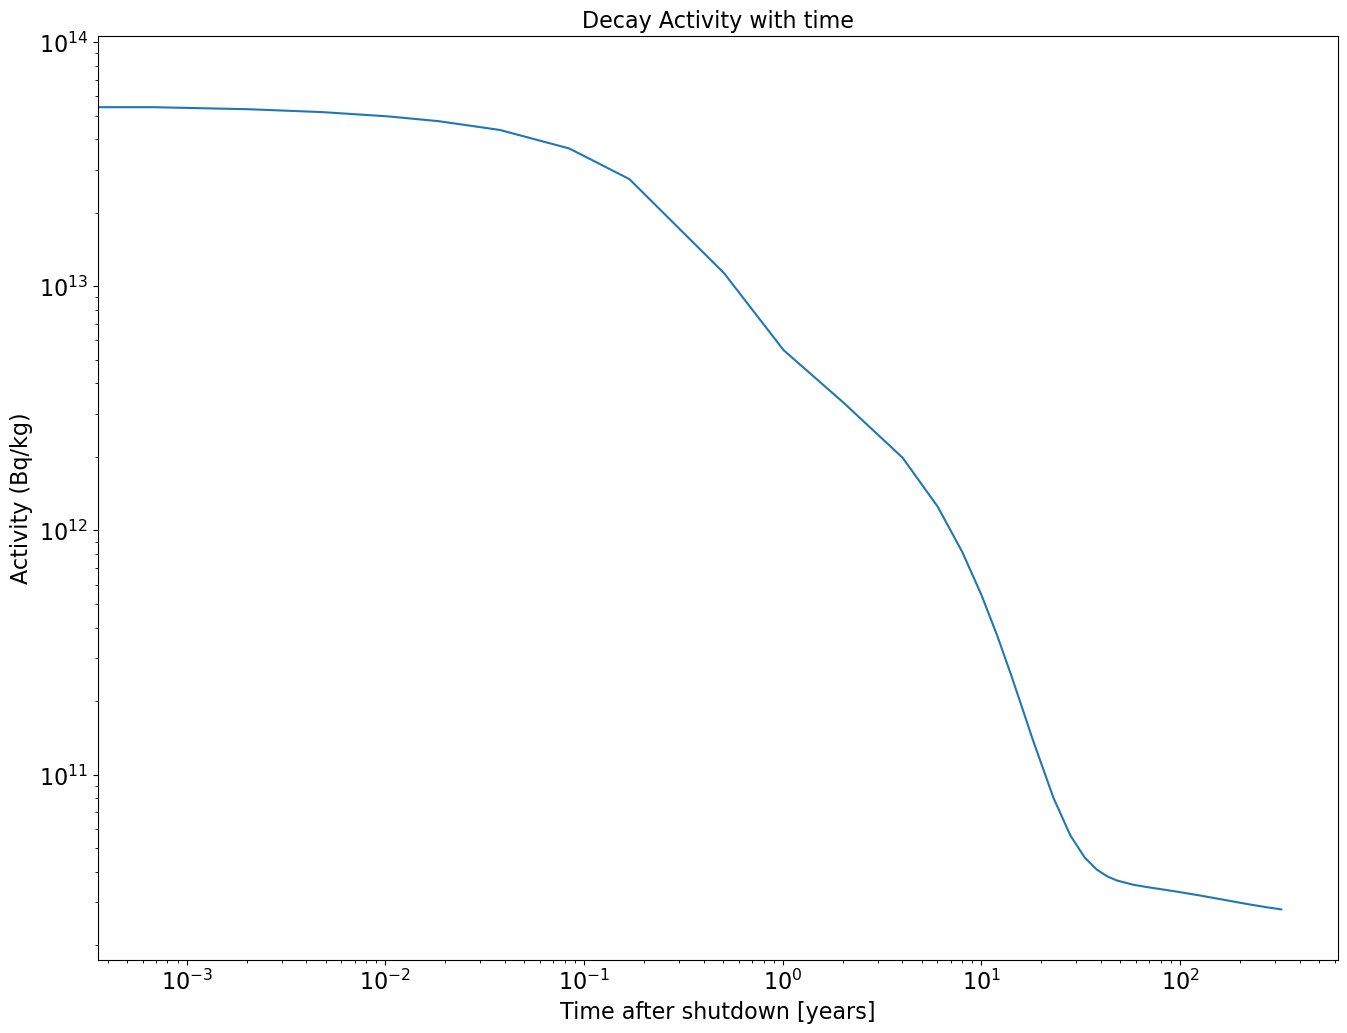

In [18]:

from openmc.deplete import chain
import matplotlib.pyplot as plt

chain = chain.Chain.from_xml('/home/davide/openmc_models/CROSS_SECTIONS/decay/chain-nndc-b8.0.xml')
nuc_all = [i.name for i in chain.nuclides]

all_activities = []
time_steps = results.get_times('s')
for counter in range(0, len(time_steps)):
    materials_at_timestep = results.export_to_materials(burnup_index=counter, nuc_with_data=nuc_all)
    #if counter == len(time_steps) - 1:
        #print(materials_at_timestep)
    activity = 0.0
    for material in materials_at_timestep:
        material.volume = FW_volume
        activity += material.get_activity(units='Bq')
    all_activities.append(activity)
#

# Calcola ciascun valore di attività diviso per kg_fw^2
attività_divise = [all_activities_i / kg_fw for all_activities_i in all_activities]

fig = plt.figure(figsize=(16, 12))
plt.loglog(time_steps[:]/s_year-1, attività_divise)
plt.xlabel('Time after shutdown [years]', fontsize=16)
plt.ylabel('Activity (Bq/kg)', fontsize=16)
plt.title('Decay Activity with time', fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()
# plt.savefig('2d_pin_cell_decay_activity.png')
